# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024160119          # <-- your full roll number
NAME = "Aryan"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160119   Name: Aryan   Fingerprint: 3E38E12B   Tickets: 16

Ticket_ID                                                                    Ticket_Text
      T01                    Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
      T02  I reinstalled the password before the assignment deadline. Please resolve it.
      T03              I can't open the Matlab after restarting the system. Please help.
      T04                                        The LMS failed to open. This is urgent.
      T05                              The server is running slowly. Can you check this?
      T06                                                Is it fixed?? Pls reply ASAP :(
      T07                                          The Wi-Fi works, but the VPN doesn't.
      T08                                       The WiFi failed to open. This is urgent.
      T09                    The email was working yesterday. I don't know what changed.
      T10         MATLAB keeps di

#Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
import pandas as pd
from collections import Counter

processed = [process_ticket(text) for text in df["Ticket_Text"]]

q1_rows = []

for ticket_id, result in zip(df["Ticket_ID"], processed):
    q1_rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": result["sentences"],
        "Tokens": result["tokens"],
        "Punctuation": result["punct"],
        "Stopwords": result["stops"],
        "Unique tokens": sorted(set(result["tokens"])),
        "Final tokens": result["final"]
    })

all_tokens = [t for r in processed for t in r["tokens"]]
all_punct = [t for r in processed for t in r["punct"]]
all_stops = [t for r in processed for t in r["stops"]]
all_final = [t for r in processed for t in r["final"]]
all_sentences = [s for r in processed for s in r["sentences"]]

q1_rows.append({
    "Ticket_ID": "TOTAL",
    "Sentences": len(all_sentences),
    "Tokens": len(all_tokens),
    "Punctuation": len(all_punct),
    "Stopwords": len(all_stops),
    "Unique tokens": len(set(all_tokens)),
    "Final tokens": len(all_final)
})

q1_table = pd.DataFrame(q1_rows)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
display(q1_table)

print("Total sentences:", len(all_sentences))
print("Total tokens:", len(all_tokens))
print("Total punctuation tokens:", len(all_punct))
print("Total stopword occurrences:", len(all_stops))
print("Corpus-wide unique tokens:", len(set(all_tokens)))
print("Total final tokens:", len(all_final))

# Investigate contraction fragments retained by the official pipeline
contraction_fragments = sorted({
    t for t in all_final
    if t in {"n't", "'s", "'re", "'ve", "'ll", "'d", "'m", "ca", "wo"}
})
print("Possible contraction fragments in final tokens:",
      contraction_fragments)

print("\nFocus ticket IDs:", FOCUS)
print("Dataset fingerprint:", FINGERPRINT)

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique tokens,Final tokens
0,T01,[Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.],"[write, to, it.helpdesk, @, thapar.edu, or, visit, www.thapar.edu/it, .]","[@, .]","[to, or]","[., @, it.helpdesk, or, thapar.edu, to, visit, write, www.thapar.edu/it]","[write, it.helpdesk, thapar.edu, visit, www.thapar.edu/it]"
1,T02,"[I reinstalled the password before the assignment deadline., Please resolve it.]","[i, reinstalled, the, password, before, the, assignment, deadline, ., please, resolve, it, .]","[., .]","[i, the, before, the, it]","[., assignment, before, deadline, i, it, password, please, reinstalled, resolve, the]","[reinstalled, password, assignment, deadline, please, resolve]"
2,T03,"[I can't open the Matlab after restarting the system., Please help.]","[i, ca, n't, open, the, matlab, after, restarting, the, system, ., please, help, .]","[., .]","[i, the, after, the]","[., after, ca, help, i, matlab, n't, open, please, restarting, system, the]","[ca, n't, open, matlab, restarting, system, please, help]"
3,T04,"[The LMS failed to open., This is urgent.]","[the, lms, failed, to, open, ., this, is, urgent, .]","[., .]","[the, to, this, is]","[., failed, is, lms, open, the, this, to, urgent]","[lms, failed, open, urgent]"
4,T05,"[The server is running slowly., Can you check this?]","[the, server, is, running, slowly, ., can, you, check, this, ?]","[., ?]","[the, is, can, you, this]","[., ?, can, check, is, running, server, slowly, the, this, you]","[server, running, slowly, check]"
5,T06,"[Is it fixed??, Pls reply ASAP :(]","[is, it, fixed, ?, ?, pls, reply, asap, :, (]","[?, ?, :, (]","[is, it]","[(, :, ?, asap, fixed, is, it, pls, reply]","[fixed, pls, reply, asap]"
6,T07,"[The Wi-Fi works, but the VPN doesn't.]","[the, wi-fi, works, ,, but, the, vpn, does, n't, .]","[,, .]","[the, but, the, does]","[,, ., but, does, n't, the, vpn, wi-fi, works]","[wi-fi, works, vpn, n't]"
7,T08,"[The WiFi failed to open., This is urgent.]","[the, wifi, failed, to, open, ., this, is, urgent, .]","[., .]","[the, to, this, is]","[., failed, is, open, the, this, to, urgent, wifi]","[wifi, failed, open, urgent]"
8,T09,"[The email was working yesterday., I don't know what changed.]","[the, email, was, working, yesterday, ., i, do, n't, know, what, changed, .]","[., .]","[the, was, i, do, what]","[., changed, do, email, i, know, n't, the, was, what, working, yesterday]","[email, working, yesterday, n't, know, changed]"
9,T10,"[MATLAB keeps disconnecting during the lab., I have tried several times!]","[matlab, keeps, disconnecting, during, the, lab, ., i, have, tried, several, times, !]","[., !]","[during, the, i, have]","[!, ., disconnecting, during, have, i, keeps, lab, matlab, several, the, times, tried]","[matlab, keeps, disconnecting, lab, tried, several, times]"


Total sentences: 29
Total tokens: 186
Total punctuation tokens: 33
Total stopword occurrences: 63
Corpus-wide unique tokens: 86
Total final tokens: 90
Possible contraction fragments in final tokens: ['ca', "n't"]

Focus ticket IDs: ['T04', 'T13']
Dataset fingerprint: 3E38E12B


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* The tokenizer splits contractions into multiple tokens. For example, isn't may become is and n't, while can't may become ca and n't. The stopword filter removes recognized stopwords but may retain fragments such as n't, ca, and 's. These are artifacts of tokenization rather than independent words in the original ticket.

#Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with , URLs with and phone numbers with . Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:

import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Extract email/URL/phone patterns for replacement.
EMAIL_RE = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
URL_RE = r"\b(?:https?://|www\.)[A-Za-z0-9.-]+(?:/[^\s.,;!?()]*)?"
PHONE_RE = r"(?<!\w)(?:\+\d{1,3}[- ]?)?(?:\d{3,5}[- ]\d{3,5}[- ]\d{3,5}|\d{10})(?!\w)"

# Number patterns preserve versions and decimals such as 2.0.1 and 95.5.
NUMBER_RE = r"(?<![\w.])\d+(?:\.\d+)+(?![\w.])|\b\d+\b"

# Word patterns.
LONG_WORD_RE = r"\b[A-Za-z]+(?:['’-][A-Za-z]+)*\b"
CAPITALIZED_RE = r"\b[A-Z][A-Za-z]*\b"
VOWEL_WORD_RE = r"\b[AEIOUaeiou][A-Za-z]*(?:['’-][A-Za-z]+)*\b"

def regex_analysis(text):
    return {
        "Longer than 5 letters": re.findall(
            r"\b[A-Za-z]{6,}\b", text
        ),
        "Numbers": re.findall(NUMBER_RE, text),
        "Capitalized words": re.findall(CAPITALIZED_RE, text),
        "Words starting with vowel": re.findall(VOWEL_WORD_RE, text)
    }

# Analyze every raw ticket.
q2_rows = []
for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    result = regex_analysis(text)
    q2_rows.append({"Ticket_ID": ticket_id, **result})

q2_table = pd.DataFrame(q2_rows)
display(q2_table)

# Test patterns on the supplied lines.
for i, line in enumerate(TEST_LINES, 1):
    print(f"\nTEST LINE {i}")
    print(regex_analysis(line))

def redact(text):
    text = re.sub(EMAIL_RE, "<EMAIL>", text)
    text = re.sub(URL_RE, "<URL>", text)
    text = re.sub(PHONE_RE, "<PHONE>", text)
    return text

print("\nRedacted TEST_LINES:")
for line in TEST_LINES:
    print(redact(line))

print("\nRedacted tickets:")
for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    print(ticket_id, redact(text))

# Capitalized words at the start of a sentence are often
# capitalized because of sentence position rather than proper nouns.
sentence_initials = []
for text in df["Ticket_Text"]:
    for sentence in nltk.sent_tokenize(text):
        match = re.match(r"\s*([A-Z][A-Za-z]*)\b", sentence)
        if match:
            sentence_initials.append(match.group(1))

print("\nCapitalized sentence-initial words:",
      sentence_initials)
print("Number of sentence-initial capitalized occurrences:",
      len(sentence_initials))

,Ticket_ID,Longer than 5 letters,Numbers,Capitalized words,Words starting with vowel
0,T01,"[helpdesk, thapar, thapar]",[],[Write],"[it, edu, or, edu, it]"
1,T02,"[reinstalled, password, before, assignment, deadline, Please, resolve]",[],"[I, Please]","[I, assignment, it]"
2,T03,"[Matlab, restarting, system, Please]",[],"[I, Matlab, Please]","[I, open, after]"
3,T04,"[failed, urgent]",[],"[The, LMS, This]","[open, is, urgent]"
4,T05,"[server, running, slowly]",[],"[The, Can]",[is]
5,T06,[],[],"[Is, Pls, ASAP]","[Is, it, ASAP]"
6,T07,[],[],"[The, Wi, Fi, VPN]",[]
7,T08,"[failed, urgent]",[],"[The, WiFi, This]","[open, is, urgent]"
8,T09,"[working, yesterday, changed]",[],"[The, I]","[email, I]"
9,T10,"[MATLAB, disconnecting, during, several]",[],"[MATLAB, I]",[I]



TEST LINE 1
{'Longer than 5 letters': ['helpdesk', 'thapar', 'thapar', 'thapar'], 'Numbers': [], 'Capitalized words': ['Mail'], 'Words starting with vowel': ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']}

TEST LINE 2
{'Longer than 5 letters': ['Version'], 'Numbers': ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250'], 'Capitalized words': ['Call', 'Version', 'Rs'], 'Words starting with vowel': ['or', 'is']}

TEST LINE 3
{'Longer than 5 letters': [], 'Numbers': ['5.30'], 'Capitalized words': ['The'], 'Words starting with vowel': ['of-the-art', "isn't", 'open', 'in', 'at']}

Redacted TEST_LINES:
Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.
Call +91 98765 43210, +91-98765-43210 or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

Redacted tickets:
T01 Write to <EMAIL> or visit <URL>.
T02 I reinstalled the password before the assignment deadl

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* The final output counts sentence-initial capitalized occurrences, but that count is not necessarily the number capitalized only because of sentence position. Words such as Python, LMS, and MATLAB may be capitalized for other reasons. Inspect the capitalized-word table alongside the original tickets and report the number you can identify as sentence-initial capitalization only.



#Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

TOKEN_PATTERN = (
    r"""https?://[^\s<>"']+"""
    r"""|www\.[^\s<>"']+"""
    r"""|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"""
    r"""|\+\d{1,3}(?:[- ]\d{2,5}){2,}"""
    r"""|\b\d{3,5}(?:-\d{2,5}){1,2}\b"""
    r"""|\b\d+(?:\.\d+)+\b"""
    r"""|\b\d+(?:,\d{3})+\b"""
    r"""|\b[A-Za-z]+(?:['’][A-Za-z]+)+\b"""
    r"""|\b[A-Za-z0-9]+(?:-[A-Za-z0-9]+)+\b"""
    r"""|\b[A-Za-z0-9]+\b"""
    r"""|[^\w\s]"""
)

my_tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)

# Compare both tokenizers on the test lines.
for i, line in enumerate(TEST_LINES, 1):
    print(f"\nTEST LINE {i}")
    print("RegexpTokenizer:", my_tokenize(line))
    print("word_tokenize:  ", word_tokenize(line))

# Compare both tokenizers on every ticket.
q3_rows = []
different_ticket_ids = []

for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    custom_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)
    differs = custom_tokens != nltk_tokens

    if differs:
        different_ticket_ids.append(ticket_id)

    q3_rows.append({
        "Ticket_ID": ticket_id,
        "Custom tokens": custom_tokens,
        "word_tokenize tokens": nltk_tokens,
        "Different?": differs
    })

q3_table = pd.DataFrame(q3_rows)
display(q3_table)

print("Tickets tokenized differently:",
      len(different_ticket_ids), "out of", len(df))
print("Ticket IDs:", different_ticket_ids)


TEST LINE 1
RegexpTokenizer: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize:   ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

TEST LINE 2
RegexpTokenizer: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize:   ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

TEST LINE 3
RegexpTokenizer: ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
word_tokenize:   ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't"

,Ticket_ID,Custom tokens,word_tokenize tokens,Different?
0,T01,"[Write, to, it.helpdesk@thapar.edu, or, visit, www.thapar.edu/it.]","[Write, to, it.helpdesk, @, thapar.edu, or, visit, www.thapar.edu/it, .]",True
1,T02,"[I, reinstalled, the, password, before, the, assignment, deadline, ., Please, resolve, it, .]","[I, reinstalled, the, password, before, the, assignment, deadline, ., Please, resolve, it, .]",False
2,T03,"[I, can't, open, the, Matlab, after, restarting, the, system, ., Please, help, .]","[I, ca, n't, open, the, Matlab, after, restarting, the, system, ., Please, help, .]",True
3,T04,"[The, LMS, failed, to, open, ., This, is, urgent, .]","[The, LMS, failed, to, open, ., This, is, urgent, .]",False
4,T05,"[The, server, is, running, slowly, ., Can, you, check, this, ?]","[The, server, is, running, slowly, ., Can, you, check, this, ?]",False
5,T06,"[Is, it, fixed, ?, ?, Pls, reply, ASAP, :, (]","[Is, it, fixed, ?, ?, Pls, reply, ASAP, :, (]",False
6,T07,"[The, Wi-Fi, works, ,, but, the, VPN, doesn't, .]","[The, Wi-Fi, works, ,, but, the, VPN, does, n't, .]",True
7,T08,"[The, WiFi, failed, to, open, ., This, is, urgent, .]","[The, WiFi, failed, to, open, ., This, is, urgent, .]",False
8,T09,"[The, email, was, working, yesterday, ., I, don't, know, what, changed, .]","[The, email, was, working, yesterday, ., I, do, n't, know, what, changed, .]",True
9,T10,"[MATLAB, keeps, disconnecting, during, the, lab, ., I, have, tried, several, times, !]","[MATLAB, keeps, disconnecting, during, the, lab, ., I, have, tried, several, times, !]",False


Tickets tokenized differently: 4 out of 16
Ticket IDs: ['T01', 'T03', 'T07', 'T09']


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Use the printed value Tickets tokenized differently. The custom tokenizer deliberately keeps items such as isn't, Wi-Fi, state-of-the-art, email addresses, and version numbers together, whereas NLTK's standard tokenizer may split these into multiple tokens. The exact count depends on your generated tickets.

## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer(r"(ing|ed|s)$", min=3)
lemmatizer = WordNetLemmatizer()

# Map Penn Treebank POS tags to WordNet POS tags.
def wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"  # adjective
    if tag.startswith("V"):
        return "v"  # verb
    if tag.startswith("N"):
        return "n"  # noun
    if tag.startswith("R"):
        return "r"  # adverb
    return "n"

unique_final_tokens = sorted(set(all_final))
tagged_tokens = dict(pos_tag(unique_final_tokens))

q4_rows = []

for word in unique_final_tokens:
    tag = tagged_tokens[word]
    wn_pos = wordnet_pos(tag)

    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regexp_stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, pos=wn_pos)

    # Display words where at least two methods produce different outputs.
    if len({p, l, r, lemma}) > 1:
        q4_rows.append({
            "Word": word,
            "POS tag": tag,
            "Porter": p,
            "Lancaster": l,
            "Regexp": r,
            "WordNet lemma": lemma
        })

q4_table = pd.DataFrame(q4_rows)
display(q4_table)

print("Unique final tokens:", len(unique_final_tokens))
print("Words with differing outputs:", len(q4_table))

# Show selected examples for closer inspection.
print("\nExamples of stemming and lemmatization:")
for word in unique_final_tokens:
    tag = tagged_tokens[word]
    wn_pos = wordnet_pos(tag)
    outputs = {
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regexp_stemmer.stem(word),
        "WordNet": lemmatizer.lemmatize(word, pos=wn_pos)
    }
    if len(set(outputs.values())) > 1:
        print(word, "->", outputs)

,Word,POS tag,Porter,Lancaster,Regexp,WordNet lemma
0,assignment,NN,assign,assign,assignment,assignment
1,changed,VB,chang,chang,chang,change
2,crashes,NNS,crash,crash,crashe,crash
3,deadline,VBP,deadlin,deadlin,deadline,deadline
4,error,NN,error,er,error,error
5,installed,VBN,instal,instal,install,instal
6,lms,NNS,lm,lms,lm,lm
7,mobile,VBP,mobil,mobl,mobile,mobile
8,open,JJ,open,op,open,open
9,opening,VBG,open,op,open,open


Unique final tokens: 57
Words with differing outputs: 28

Examples of stemming and lemmatization:
assignment -> {'Porter': 'assign', 'Lancaster': 'assign', 'Regexp': 'assignment', 'WordNet': 'assignment'}
changed -> {'Porter': 'chang', 'Lancaster': 'chang', 'Regexp': 'chang', 'WordNet': 'change'}
crashes -> {'Porter': 'crash', 'Lancaster': 'crash', 'Regexp': 'crashe', 'WordNet': 'crash'}
deadline -> {'Porter': 'deadlin', 'Lancaster': 'deadlin', 'Regexp': 'deadline', 'WordNet': 'deadline'}
error -> {'Porter': 'error', 'Lancaster': 'er', 'Regexp': 'error', 'WordNet': 'error'}
installed -> {'Porter': 'instal', 'Lancaster': 'instal', 'Regexp': 'install', 'WordNet': 'instal'}
lms -> {'Porter': 'lm', 'Lancaster': 'lms', 'Regexp': 'lm', 'WordNet': 'lm'}
mobile -> {'Porter': 'mobil', 'Lancaster': 'mobl', 'Regexp': 'mobile', 'WordNet': 'mobile'}
open -> {'Porter': 'open', 'Lancaster': 'op', 'Regexp': 'open', 'WordNet': 'open'}
opening -> {'Porter': 'open', 'Lancaster': 'op', 'Regexp': 'open', '

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* one over-stemming and one under-stemming example

Use your actual output table to select examples:

Over-stemming: a stemmer removes too much and produces an unnatural or misleading root. Lancaster may do this for some words.

Under-stemming: related words remain different even though they share a meaningful root. For example, a stemmer might fail to equate a noun and a related verb.



#Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Corpus,Total tokens,Unique tokens,TTR
0,S1: All tokens,186,86,0.4624
1,S2: No punctuation,153,79,0.5163
2,S3: Final tokens,90,57,0.6333
3,S4: Porter stems,90,54,0.6000



Top 10 words in S1:
.                    24
the                  15
i                    7
is                   7
it                   5
please               4
yesterday            4
to                   3
password             3
n't                  3

Top 10 words in S3:
please               4
yesterday            4
password             3
n't                  3
open                 3
tried                3
showing              3
error                3
assignment           2
deadline             2


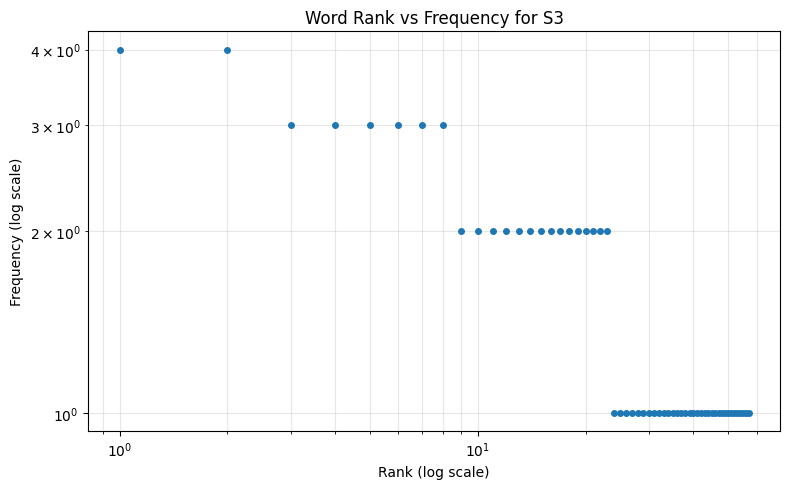


Top 5 bigrams in S1:
('.', 'i'): 5
('.', 'the'): 5
('.', 'please'): 4
('yesterday', '.'): 4
('is', 'showing'): 3

Top 5 bigrams in S3:
('showing', 'error'): 3
('assignment', 'deadline'): 2
('deadline', 'please'): 2
('please', 'resolve'): 2
('please', 'help'): 2

S3 unique words: 57
S4 unique stems: 54
S3 TTR: 0.6333
S4 TTR: 0.6


In [9]:
import math
import matplotlib.pyplot as plt
from nltk.util import bigrams
from collections import Counter

# S1: all lowercase tokens, including punctuation and stopwords
S1 = all_tokens

# S2: remove punctuation tokens only
S2 = [t for t in S1 if not is_punct(t)]

# S3: official preprocessing output
S3 = all_final

# S4: Porter-stemmed version of S3
S4 = [porter.stem(t) for t in S3]

def corpus_stats(name, tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0
    return {
        "Corpus": name,
        "Total tokens": total,
        "Unique tokens": unique,
        "TTR": round(ttr, 4)
    }

stats_table = pd.DataFrame([
    corpus_stats("S1: All tokens", S1),
    corpus_stats("S2: No punctuation", S2),
    corpus_stats("S3: Final tokens", S3),
    corpus_stats("S4: Porter stems", S4)
])

print("CORPUS STATISTICS")
display(stats_table)

def show_top_words(name, tokens, n=10):
    print(f"\nTop {n} words in {name}:")
    for word, freq in Counter(tokens).most_common(n):
        print(f"{word:<20} {freq}")

show_top_words("S1", S1, 10)
show_top_words("S3", S3, 10)

# Log(rank) versus log(frequency) for S3.
freqs = Counter(S3).most_common()
ranks = list(range(1, len(freqs) + 1))
frequencies = [freq for word, freq in freqs]

plt.figure(figsize=(8, 5))
plt.loglog(ranks, frequencies, marker="o", linestyle="none",
           markersize=4)
plt.xlabel("Rank (log scale)")
plt.ylabel("Frequency (log scale)")
plt.title("Word Rank vs Frequency for S3")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

def show_top_bigrams(name, tokens, n=5):
    counts = Counter(bigrams(tokens))
    print(f"\nTop {n} bigrams in {name}:")
    for pair, freq in counts.most_common(n):
        print(f"{pair}: {freq}")

show_top_bigrams("S1", S1, 5)
show_top_bigrams("S3", S3, 5)

# Extra: verify how stemming changes vocabulary size.
print("\nS3 unique words:", len(set(S3)))
print("S4 unique stems:", len(set(S4)))
print("S3 TTR:", round(len(set(S3)) / len(S3), 4) if S3 else 0)
print("S4 TTR:", round(len(set(S4)) / len(S4), 4) if S4 else 0)

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*  S1 to S2: Removing punctuation changes both the total token count and potentially the proportion of unique tokens.

S2 to S3: Removing stopwords eliminates frequent function words, while punctuation has already been excluded. This changes the vocabulary and token totals.

S3 to S4: Porter stemming merges some related word forms into the same stem. The number of tokens remains unchanged, but the number of unique forms usually decreases, so TTR generally decreases or stays the same.

